<a href="https://colab.research.google.com/github/tomasolvs/master-ai-gestion-proyectos-ai-actividad-4/blob/main/TO_Modulo_2_Actividad_4_Gesti%C3%B3n_de_proyectos_de_inteligencia_artificial_191026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gestión de proyectos de inteligencia artificial
## Semana 5, Módulo 2, Actividad 4
## Tomás Olivares - 19/10/26

### Actividad 4: Prototipo de clasificación de reseñas por medio de NLP

# Actividad 4 — Comparación de modelos preentrenados para análisis de sentimiento
**Caso de uso:** clasificación de reseñas de restaurante en español (positivo, neutral, negativo).

Este notebook compara tres modelos de Hugging Face con un dataset pequeño, balanceado y **sintético**. Los resultados miden el comportamiento en este conjunto de prueba, no representan una garantía de desempeño en reseñas reales. Para una decisión de producción se necesita una muestra real, representativa y revisada por personas.

**Reproducibilidad:** ejecutar las celdas en orden en Google Colab. Seleccionar `Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU`. Las métricas y latencias se calculan al ejecutar; no se incluyen números inventados.

## 1. Configuración de GPU y dependencias
Se verifica el acelerador disponible. En Colab, selecciona una GPU antes de continuar. Si no hay GPU, el notebook seguirá en CPU, pero las latencias no serán comparables con una ejecución en GPU.

In [10]:
!nvidia-smi
%pip install -q "pandas==2.2.3" transformers accelerate evaluate scikit-learn matplotlib huggingface_hub

Tue Oct 20 06:30:38 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P0             27W /   70W |     153MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Simulación de autenticación opcional con Hugging Face Hub
Los tres modelos son públicos y normalmente pueden descargarse sin token. La autenticación se incluye con fines informativos (como código comentado, no ejecutado) para cumplir el flujo de trabajo del tema y permitir acceso a recursos con permisos. Se debería guardar el token en `Colab Secrets` como `HF_TOKEN`; no se debería escribir directamente en el notebook ni subirse a GitHub.

In [9]:
"""
import os
from getpass import getpass

try:
    from google.colab import userdata
    token = userdata.get("HF_TOKEN")
except Exception:
    token = None

if not token:
    print("No se encontró HF_TOKEN en Colab Secrets. Para modelos públicos, puedes continuar sin autenticarte.")
else:
    from huggingface_hub import login
    login(token=token, add_to_git_credential=False)
    print("Autenticación realizada sin mostrar el token.")
"""

'\nimport os\nfrom getpass import getpass\n\ntry:\n    from google.colab import userdata\n    token = userdata.get("HF_TOKEN")\nexcept Exception:\n    token = None\n\nif not token:\n    print("No se encontró HF_TOKEN en Colab Secrets. Para modelos públicos, puedes continuar sin autenticarte.")\nelse:\n    from huggingface_hub import login\n    login(token=token, add_to_git_credential=False)\n    print("Autenticación realizada sin mostrar el token.")\n'

## 3. Carga del dataset y revisión
El archivo `data/resenas_restaurante.csv` contiene 90 ejemplos creados específicamente para esta práctica: 30 positivos, 30 negativos y 30 neutrales. La fuente es un script incluido en `src/generar_dataset.py`; no son opiniones reales de clientes.

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display

DATA_PATH = Path("/content/resenas_restaurante.csv")
if not DATA_PATH.exists():
    # Si el notebook está abierto desde una carpeta local o repositorio, intenta rutas habituales.
    candidates = [Path("data/resenas_restaurante.csv"), Path("../data/resenas_restaurante.csv")]
    for candidate in candidates:
        if candidate.exists():
            DATA_PATH = candidate
            break

if not DATA_PATH.exists():
    from google.colab import files
    uploaded = files.upload()  # seleccionar resenas_restaurante.csv
    DATA_PATH = Path("resenas_restaurante.csv")

df = pd.read_csv(DATA_PATH)
required = {"texto", "etiqueta"}
assert required.issubset(df.columns), f"Faltan columnas requeridas: {required - set(df.columns)}"
df = df.dropna(subset=["texto", "etiqueta"]).copy()
df["etiqueta"] = df["etiqueta"].str.upper().str.strip()
df = df[df["etiqueta"].isin(["POS", "NEG", "NEU"])].reset_index(drop=True)
display(df.head())
display(df["etiqueta"].value_counts().rename_axis("etiqueta").to_frame("registros"))
print(f"Registros evaluables: {len(df)}")

Saving resenas_restaurante.csv to resenas_restaurante.csv


,id,texto,etiqueta,etiqueta_nombre
0,1,La comida estuvo deliciosa y el mesero fue muy...,POS,positivo
1,2,"Excelente experiencia, volveremos sin duda.",POS,positivo
2,3,El café estaba perfecto y el pan recién hecho.,POS,positivo
3,4,Todo llegó caliente y las porciones fueron gen...,POS,positivo
4,5,La atención fue rápida y el lugar estaba impec...,POS,positivo


,registros
etiqueta,
POS,30
NEG,30
NEU,30


Registros evaluables: 90


## 4. Criterios de selección
- Compatibilidad con español y salida de sentimiento.
- Capacidad de mapear las etiquetas a POS/NEG/NEU.
- Latencia promedio por reseña.
- Métricas macro para evitar que una clase domine la comparación.
- Tamaño aproximado, licencia y dominio de entrenamiento, revisados en las fichas de los modelos.

**Advertencia metodológica:** el conjunto sintético es pequeño y sencillo; sus métricas sirven para comprobar el pipeline y comparar esta muestra, pero no son un benchmark independiente ni representativo de clientes reales.

In [3]:
from transformers import pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import time, gc, torch

MODEL_IDS = [
    "pysentimiento/robertuito-sentiment-analysis",
    "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "cardiffnlp/twitter-xlm-roberta-base-sentiment",
]

# Normaliza nombres distintos de las salidas de los modelos.
def normalize_label(label):
    x = str(label).strip().lower()
    if x in {"pos", "positive", "label_2", "5 stars", "4 stars"} or "positive" in x:
        return "POS"
    if x in {"neg", "negative", "label_0", "1 star", "2 stars"} or "negative" in x:
        return "NEG"
    if x in {"neu", "neutral", "label_1", "3 stars"} or "neutral" in x:
        return "NEU"
    # Etiquetas habituales de RoBERTuito
    if x == "pos": return "POS"
    if x == "neg": return "NEG"
    if x == "neu": return "NEU"
    raise ValueError(f"Etiqueta no reconocida: {label!r}. Revisa config.id2label del modelo.")

def predict_one(pipe, text):
    result = pipe(str(text), truncation=True, max_length=256)[0]
    return normalize_label(result["label"]), float(result["score"])

## 5. Inferencia, métricas y latencia
La latencia se mide secuencialmente por texto, tras cargar el modelo. Se excluye la descarga inicial y la carga en memoria; por ello representa latencia de inferencia local aproximada, no el tiempo total de despliegue. En GPU se sincroniza CUDA para medir correctamente.

In [4]:
results = []
predictions_by_model = {}

device = 0 if torch.cuda.is_available() else -1
print("Dispositivo:", torch.cuda.get_device_name(0) if device == 0 else "CPU")

for model_id in MODEL_IDS:
    print(f"\nCargando {model_id}")
    pipe = pipeline("text-classification", model=model_id, device=device)
    y_true = df["etiqueta"].tolist()
    y_pred, confidences, latencies = [], [], []

    # Calentamiento: no se incluye en latencia
    _ = pipe(str(df.iloc[0]["texto"]), truncation=True, max_length=256)
    if device == 0:
        torch.cuda.synchronize()

    for text in df["texto"].tolist():
        if device == 0:
            torch.cuda.synchronize()
        start = time.perf_counter()
        label, confidence = predict_one(pipe, text)
        if device == 0:
            torch.cuda.synchronize()
        elapsed_ms = (time.perf_counter() - start) * 1000
        y_pred.append(label)
        confidences.append(confidence)
        latencies.append(elapsed_ms)

    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=["POS", "NEU", "NEG"], average="macro", zero_division=0
    )
    results.append({
        "modelo": model_id,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision,
        "recall_macro": recall,
        "f1_macro": f1,
        "latencia_media_ms": float(np.mean(latencies)),
        "latencia_p50_ms": float(np.percentile(latencies, 50)),
        "latencia_p95_ms": float(np.percentile(latencies, 95)),
        "confianza_media": float(np.mean(confidences)),
        "dispositivo": "GPU" if device == 0 else "CPU",
        "n_muestras": len(y_true)
    })
    predictions_by_model[model_id] = y_pred
    print(classification_report(y_true, y_pred, labels=["POS","NEU","NEG"], zero_division=0))
    del pipe
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

results_df = pd.DataFrame(results).sort_values(["f1_macro", "latencia_media_ms"], ascending=[False, True])
display(results_df)
results_df.to_csv("comparacion_modelos.csv", index=False)

Dispositivo: Tesla T4

Cargando pysentimiento/robertuito-sentiment-analysis


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

              precision    recall  f1-score   support

         POS       1.00      0.87      0.93        30
         NEU       0.76      0.97      0.85        30
         NEG       0.92      0.80      0.86        30

    accuracy                           0.88        90
   macro avg       0.90      0.88      0.88        90
weighted avg       0.90      0.88      0.88        90



,modelo,accuracy,precision_macro,recall_macro,f1_macro,latencia_media_ms,latencia_p50_ms,latencia_p95_ms,confianza_media,dispositivo,n_muestras
2,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.877778,0.895412,0.877778,0.879552,13.672451,13.223456,17.504556,0.780608,GPU,90
0,pysentimiento/robertuito-sentiment-analysis,0.844444,0.893939,0.844444,0.848887,10.335584,9.939932,12.498178,0.816381,GPU,90
1,lxyuan/distilbert-base-multilingual-cased-sent...,0.477778,0.367381,0.477778,0.397436,5.665240,5.481774,7.338878,0.643689,GPU,90


## 6. Comparación y visualización
Se recomienda priorizar F1 macro y revisar por separado los errores por clase. Una latencia menor no compensa necesariamente un recall bajo en una clase crítica.

,modelo,accuracy,precision_macro,recall_macro,f1_macro,latencia_media_ms
2,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.877778,0.895412,0.877778,0.879552,13.672451
0,pysentimiento/robertuito-sentiment-analysis,0.844444,0.893939,0.844444,0.848887,10.335584
1,lxyuan/distilbert-base-multilingual-cased-sent...,0.477778,0.367381,0.477778,0.397436,5.665240


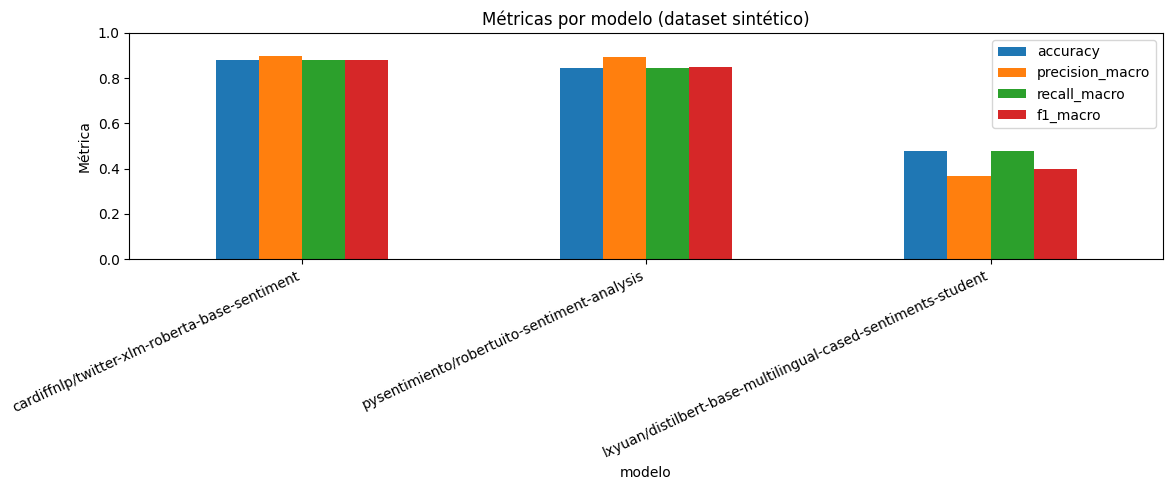

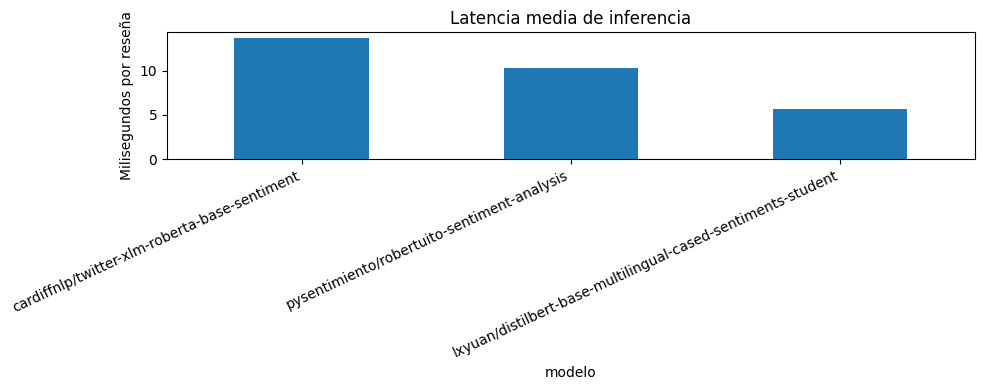

In [5]:
import matplotlib.pyplot as plt

display(results_df[["modelo", "accuracy", "precision_macro", "recall_macro", "f1_macro", "latencia_media_ms"]])
ax = results_df.plot(x="modelo", y=["accuracy", "precision_macro", "recall_macro", "f1_macro"], kind="bar", figsize=(12,5))
ax.set_ylim(0, 1)
ax.set_ylabel("Métrica")
ax.set_title("Métricas por modelo (dataset sintético)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

ax = results_df.plot(x="modelo", y="latencia_media_ms", kind="bar", figsize=(10,4), legend=False)
ax.set_ylabel("Milisegundos por reseña")
ax.set_title("Latencia media de inferencia")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

In [6]:
## 7. Matrices de confusión y errores

for model_id, y_pred in predictions_by_model.items():
    cm = confusion_matrix(df["etiqueta"], y_pred, labels=["POS", "NEU", "NEG"])
    print("\n", model_id)
    display(pd.DataFrame(cm, index=["Real POS","Real NEU","Real NEG"], columns=["Pred POS","Pred NEU","Pred NEG"]))


 pysentimiento/robertuito-sentiment-analysis


,Pred POS,Pred NEU,Pred NEG
Real POS,23,7,0
Real NEU,0,30,0
Real NEG,0,7,23



 lxyuan/distilbert-base-multilingual-cased-sentiments-student


,Pred POS,Pred NEU,Pred NEG
Real POS,25,0,5
Real NEU,27,0,3
Real NEG,9,3,18



 cardiffnlp/twitter-xlm-roberta-base-sentiment


,Pred POS,Pred NEU,Pred NEG
Real POS,26,3,1
Real NEU,0,29,1
Real NEG,0,6,24


## 8. Conclusiones parciales y decisión
La recomendación final debe basarse en los valores generados al ejecutar este notebook, no en una predicción previa de cuál modelo ganará. Selecciona el modelo que combine F1 macro suficiente, latencia aceptable y una licencia compatible con el uso previsto.

**Umbrales iniciales propuestos para un prototipo:** F1 macro ≥ 0.80 y latencia media ≤ 250 ms por reseña en el hardware de prueba. Son criterios de proyecto, no resultados obtenidos. Si ninguno los cumple, no debe declararse un ganador de producción: ampliar y validar el dataset, revisar errores y considerar ajustes mínimos o fine-tuning.

**Riesgos:** dataset sintético y pequeño; dominio de entrenamiento basado en redes sociales; sarcasmo, ironía, modismos regionales, reseñas mixtas y sesgo de clase. Antes de producción, evaluar una muestra real etiquetada por humanos, documentar el hardware y repetir la medición varias veces.

In [8]:
# Exporta las predicciones por reseña para auditoría
audit = df[["id", "texto", "etiqueta"]].copy()
for model_id, preds in predictions_by_model.items():
    audit[model_id.split("/")[-1]] = preds
audit.to_csv("predicciones_por_resena.csv", index=False, encoding="utf-8-sig")
display(audit.head(10))
print("Archivos generados: comparacion_modelos.csv y predicciones_por_resena.csv")

,id,texto,etiqueta,robertuito-sentiment-analysis,distilbert-base-multilingual-cased-sentiments-student,twitter-xlm-roberta-base-sentiment
0,1,La comida estuvo deliciosa y el mesero fue muy...,POS,POS,POS,POS
1,2,"Excelente experiencia, volveremos sin duda.",POS,POS,POS,POS
2,3,El café estaba perfecto y el pan recién hecho.,POS,POS,POS,POS
3,4,Todo llegó caliente y las porciones fueron gen...,POS,NEU,POS,POS
4,5,La atención fue rápida y el lugar estaba impec...,POS,POS,POS,POS
5,6,"Me encantó la pasta, tenía mucho sabor.",POS,POS,POS,POS
6,7,Muy buena relación calidad precio.,POS,POS,POS,POS
7,8,El personal resolvió nuestro problema de inmed...,POS,NEU,NEG,NEU
8,9,"Los postres son espectaculares, especialmente ...",POS,POS,POS,POS
9,10,La terraza es agradable y la música estaba a b...,POS,POS,POS,POS


Archivos generados: comparacion_modelos.csv y predicciones_por_resena.csv


## 9. Referencias
- RoBERTuito sentiment: https://huggingface.co/pysentimiento/robertuito-sentiment-analysis
- DistilBERT multilingual sentiment student: https://huggingface.co/lxyuan/distilbert-base-multilingual-cased-sentiments-student
- CardiffNLP Twitter XLM-RoBERTa sentiment: https://huggingface.co/cardiffnlp/twitter-xlm-roberta-base-sentiment
- Hugging Face Transformers: https://huggingface.co/docs/transformers
- Scikit-learn metrics: https://scikit-learn.org/stable/modules/model_evaluation.html

Revisar las fichas vigentes para confirmar licencia, condiciones de redistribución y limitaciones antes de un uso comercial.
